In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# task 1
df =pd.read_csv("AI usage.csv")
print(df.shape)
df.info()
df.isna()
print(df.isna().sum())
df.value_counts()
print(df.nunique())

(300, 19)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    str    
 1   Age                          277 non-null    str    
 2   Gender                       290 non-null    str    
 3   Country                      290 non-null    str    
 4   User_Type                    300 non-null    str    
 5   Education_Level              287 non-null    str    
 6   Profession                   285 non-null    str    
 7   Monthly_Income               290 non-null    str    
 8   AI_Tool                      289 non-null    str    
 9   AI_Purpose                   287 non-null    str    
 10  AI_Usage_Hours_Per_Day       293 non-null    str    
 11  Tasks_Performed              282 non-null    str    
 12  Monthly_AI_Cost              288 non-null    str    
 13  Productivity_Score   

In [3]:
print(df.nunique())

User_ID                        288
Age                             52
Gender                          11
Country                         20
User_Type                        2
Education_Level                 16
Profession                     126
Monthly_Income                 233
AI_Tool                         16
AI_Purpose                       8
AI_Usage_Hours_Per_Day          89
Tasks_Performed                270
Monthly_AI_Cost                 12
Productivity_Score              73
Accuracy_Rating                  4
Satisfaction_Score               8
Time_Saved_Hours_Per_Week      133
Work_or_Study_Hours_Per_Day     93
Would_Recommend                  3
dtype: int64


In [4]:
# task 2
for col in ["Gender",	"Country",	"User_Type",	"Education_Level"	,"Profession","AI_Tool","AI_Purpose","Tasks_Performed","Would_Recommend"]:
    print(col)
    print(df[col].value_counts(dropna=False))
    print("_"*3)

Gender
Gender
Male          122
Female        105
male           12
Other          12
M              11
NaN            10
F              10
MALE            6
FEMALE          5
other           3
female          3
Non-binary      1
Name: count, dtype: int64
___
Country
Country
India                       42
United States               34
Canada                      32
Pakistan                    29
United Kingdom              26
Philippines                 24
Brazil                      23
Australia                   20
Nigeria                     17
Germany                     13
NaN                         10
France                      10
Kenya                        6
brazil                       4
india                        3
canada                       2
france                       1
U.K.                         1
United States of America     1
philippines                  1
australia                    1
Name: count, dtype: int64
___
User_Type
User_Type
Student         158
Pro

<!-- problems found in the data -->

**Duplicate rows**
1.User_id = 300 rows but 288 are unique so have to check the repeated values

**inconsistent value**
-Gender - 'MALE','Male','male','M','m' -> Male,
| 'FEMALE','Female',female','F','f' -> False
-Country - 'brazil','india',united states','canada','u.k' ,'australia','france','phillippines' are in the lowercase have to change them 
-Education_level -
'Bachelor's','bachelors''bachelor's degree' ->'Bachelor's'|

'Mater's', 'Maters','master's degree', -> 'Maters'|

'Undergraduate','undergrad' -> 'Undergraduate'|

'phD','ph.D.' -> 'pdD'
'high school' is in lower case have to change
-AI_TOOL - 'ChatGpt','chatgpt','Chatgpt','Chat GPT' -> 'Chatgpt' |
 'Claude','claude'->'Claude' |
  'Micorsoft copilot','copilot','Copilot'-> 'Copilot', |
'Google Gemini','Gemini','gemini' -> 'Gemini'


**language issues**
- another language used here (analista de Dados),Desenvolvedor de Sistemas (Systems Developer) 


**missing values(na)**
-null values -
gender- 10 
country - 10
Education_level - 13
profession -15
AI_Tool- 11
AI_purpose - 13
Would_Recommend - 5



In [5]:
print(df[df["Education_Level"] == "Undergraduate"]["User_Type"].value_counts())

User_Type
Student    61
Name: count, dtype: int64


In [6]:
print(df[df["Education_Level"] == "Bachelor's"]["User_Type"].value_counts())

User_Type
Professional    50
Student         21
Name: count, dtype: int64


- Education_Level: "Undergraduate" (61 rows, all Students) kept separate from "Bachelor's" (71 rows, 50 Professionals / 21 Students). Most Bachelor's holders are working, so it likely means a completed degree. Some overlap is possible among the 21 Students.

In [7]:
print(df.duplicated().sum())

12


In [8]:
df =df.drop_duplicates()
print(df.shape)
print(df["User_ID"].nunique())
print(df["User_ID"].duplicated().sum())


(288, 19)
288
0


- Duplicates: 12 rows were exact copies (all 19 columns identical), dropped. 300 -> 288 rows.

In [9]:
df = df.reset_index(drop=True)


In [10]:
df["Gender"] = df["Gender"].str.strip().str.lower()
print(df["Gender"].value_counts(dropna=False))  

Gender
male          134
female        107
other          15
m              11
NaN            10
f              10
non-binary      1
Name: count, dtype: int64


In [11]:
gender_map = {
    "m": "Male",
    "male": "Male",
    "f": "Female",
    "female":"Female",
    "other" : "Other",
    "non-binary": "Non-Binary",
}

df["Gender"] = df["Gender"].replace(gender_map)
print(df["Gender"].value_counts(dropna=False))

Gender
Male          145
Female        117
Other          15
NaN            10
Non-Binary      1
Name: count, dtype: int64


In [12]:
df["Country"]= df["Country"].str.strip().str.title()
print(df["Country"].value_counts(dropna=False))

Country
India                       43
United States               33
Canada                      31
Pakistan                    28
Brazil                      26
United Kingdom              25
Philippines                 24
Australia                   20
Nigeria                     17
Germany                     13
France                      10
NaN                         10
Kenya                        6
U.K.                         1
United States Of America     1
Name: count, dtype: int64


In [13]:
Country_map = {
    "U.K." : "United Kingdom",
    "United States Of America":"United States",

}

df["Country"] = df["Country"].replace(Country_map)
df["Country"].value_counts()

Country
India             43
United States     34
Canada            31
Pakistan          28
United Kingdom    26
Brazil            26
Philippines       24
Australia         20
Nigeria           17
Germany           13
France            10
Kenya              6
Name: count, dtype: int64

In [14]:
df["Education_Level"]=df["Education_Level"].str.strip().str.title()
df["Education_Level"].value_counts(dropna=False)

Education_Level
Bachelor'S           69
Undergraduate        60
Master'S             48
High School          45
Diploma              25
Phd                  14
NaN                  12
Undergrad             3
Ba/Bsc                2
Ph.D.                 2
Masters               2
Bachelors             2
Ma/Msc                1
Master'S Degree       1
Bachelor'S Degree     1
Hs                    1
Name: count, dtype: int64

In [15]:
Education_Level_map ={
    "Bachelor'S" : "Bachelors",
    "Bachelor'S Degree" : "Bachelors",
    "Undergrad":"Undergraduate",
    "Master'S":"Masters",
    "Master'S Degree":"Masters",
    "Ph.D.":"phd",
    "Phd":"phd",
    "Hs":"High School",
}

df["Education_Level"] = df["Education_Level"].replace(Education_Level_map)
df["Education_Level"].value_counts(dropna=False)


Education_Level
Bachelors        72
Undergraduate    63
Masters          51
High School      46
Diploma          25
phd              16
NaN              12
Ba/Bsc            2
Ma/Msc            1
Name: count, dtype: int64

In [16]:
df["AI_Tool"] = df["AI_Tool"].str.strip().str.title()
df["AI_Tool"].value_counts(dropna=False)

AI_Tool
Chatgpt              116
Google Gemini         37
Claude                31
Microsoft Copilot     30
Perplexity Ai         23
Grammarly             14
Meta Ai               10
NaN                   10
Deepseek               9
Chat Gpt               3
Copilot                3
Gemini                 2
Name: count, dtype: int64

In [17]:
AI_Tool_map={
    "Chat Gpt":"Chatgpt",
    "Microsoft Copilot":"Copilot",
    "Google Gemini":"Gemini",
}

df["AI_Tool"]=df["AI_Tool"].replace(AI_Tool_map)
df["AI_Tool"].value_counts(dropna="False")

AI_Tool
Chatgpt          119
Gemini            39
Copilot           33
Claude            31
Perplexity Ai     23
Grammarly         14
Meta Ai           10
Deepseek           9
Name: count, dtype: int64

to make it more professional i capitalize some words

In [18]:
df["AI_Tool"] = df["AI_Tool"].replace({
    "Chatgpt": "ChatGPT",
    "Meta Ai": "Meta AI",
    "Perplexity Ai": "Perplexity AI",
    "Deepseek": "DeepSeek",
})

In [19]:
df["Profession"]=df["Profession"].str.strip().str.title()
df["Profession"].value_counts(dropna=False)

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Analista De Dados                                    1
Multimedia Content Producer                          1
Desenvolvedor De Sistemas (Systems Developer)        1
Name: count, Length: 127, dtype: int64

In [20]:
Profession_map={
    "Analista De Dados" : "Data Analayst",
    "Desenvolvedor De Sistemas (Systems Developer)":"Sytem Developer",

}

df["Profession"] = df["Profession"].replace(Profession_map)
df["Profession"].value_counts(dropna=False)

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Data Analayst                                        1
Multimedia Content Producer                          1
Sytem Developer                                      1
Name: count, Length: 127, dtype: int64

In [21]:
df["Profession"]= df["Profession"].replace(Profession_map)
df["Profession"].value_counts(dropna=False)

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Data Analayst                                        1
Multimedia Content Producer                          1
Sytem Developer                                      1
Name: count, Length: 127, dtype: int64

In [22]:
fix_map = {
    "Data Analayst": "Data Analyst",
    "Ssystem Developer": "Systems Developer",
}
df["Profession"] = df["Profession"].replace(fix_map)
print(df["Profession"].value_counts(dropna=False))

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Analyste De Données / Data Analyst                   1
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Multimedia Content Producer                          1
Sytem Developer                                      1
Name: count, Length: 126, dtype: int64


In [23]:
fix_map = {
    "Ssytem Developer": "Systems Developer",
}
df["Profession"] = df["Profession"].replace(fix_map)

In [24]:
for p in sorted(df["Profession"].dropna().unique()):
    print(p)

Academic Research Professor And Technical Writer
Administrative Assistant
Administrative Executive
Ai Content Strategist
Ai Customer Success Manager
Ai Customer Support Specialist
Ai-Powered Customer Support Executive
Analista De Dados Sênior
Analyste De Données / Data Analyst
Artificial Intelligence & Digital Media Student
Artificial Intelligence And Machine Learning Student
Artificial Intelligence Research Student
Assistente Administrativo
Bioinformatics Student
Biology Student
Biomedical Engineering Student
Biomedical Science Student
Biotechnology Phd Student
Biotechnology Student
Business Administration Student
Business Analyst
Business Analytics Student
Business Intelligence Analyst
Computer Science Phd Student
Computer Science Student
Content Creator/Gestor De Conteúdo Digital
Content Manager
Content Marketing Manager
Content Strategist
Content Strategist & Technical Writer
Content Strategy Manager
Content Writer
Creative Writing Student
Customer Experience Manager
Customer Servi

In [25]:
print(df.loc[df["Profession"].str.contains(r"\x00-\x7F",na=False),"Profession"].unique())

<StringArray>
[]
Length: 0, dtype: str


In [26]:
vc = df["Profession"].value_counts()
print(vc[vc == 1].index.tolist())

['Desenvolvedora De Software / Software Developer', 'Développeur Full Stack', 'Social Media Content Creator', 'Customer Service Representative', 'Ai-Powered Customer Support Executive', 'Kundenservice-Spezialistin / Customer Service Specialist', 'Digital Content Creator', 'Pesquisador De Mercado', 'Data Analytics Manager', 'Engenheiro De Software Sênior / Tech Lead', 'Senior Software Engineer / Technical Lead', 'Research Scientist/Senior Research Officer', 'Artificial Intelligence And Machine Learning Student', 'Social Media Content Creator / Digital Marketer', 'Responsable De Contenu Digital', 'Marketing Communications Officer', 'Desenvolvedor De Software Sênior', 'Digital Media And Communications Student', 'Bioinformatics Student', 'Senior Software Engineer / Ai Solutions Architect', 'Senior Software Developer / Softwareentwicklerin', 'Data Entry Specialist', 'Data Entry Operator', 'Artificial Intelligence Research Student', 'Digital Content Strategist', 'Senior Machine Learning Engi

In [27]:
pip install langdetect

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:

from langdetect import detect

def lang(x):
    try:
        return detect(x)
    except:
        return "unknown"

profs = pd.Series(df["Profession"].dropna().unique())
langs = profs.apply(lang)
print(profs[langs != "en"].tolist())

['Desenvolvedora De Software / Software Developer', 'Développeur Full Stack', 'Social Media Content Creator', 'Data Analyst', 'Kundenservice-Spezialistin / Customer Service Specialist', 'Digital Content Creator', 'Pesquisador De Mercado', 'Business Administration Student', 'Engineering Student', 'Data Analytics Manager', 'Engenheiro De Software Sênior / Tech Lead', 'Content Writer', 'Responsable De Contenu Digital', 'Digital Media Student', 'Desenvolvedor De Software Sênior', 'Environmental Science Student', 'Digital Content Strategist', 'Molecular Biology Student', 'Senior Data Scientist', 'Content Strategist & Technical Writer', 'German Literature Student', 'Software Development Student', 'Especialista Em Atendimento Ao Cliente Com Ia', 'Administrative Executive', 'Data Science Student', 'Desenvolvedora De Sistemas Júnior', 'Digital Marketing Student', 'Content Manager', 'Gerente De Atendimento Ao Cliente', 'Content Creator/Gestor De Conteúdo Digital', 'Kundenbetreuerin Mit Ki-Unters

In [29]:
fix_map = {
    "Data Analayst": "Data Analyst",
    "Ssystem Developer": "Systems Developer",
}
df["Profession"] = df["Profession"].replace(fix_map)
print(df["Profession"].value_counts(dropna=False))

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Analyste De Données / Data Analyst                   1
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Multimedia Content Producer                          1
Sytem Developer                                      1
Name: count, Length: 126, dtype: int64


In [30]:
fix_map = {
    "Ssytem Developer": "Systems Developer",
}
df["Profession"] = df["Profession"].replace(fix_map)
print(df["Profession"].value_counts(dropna=False))

Profession
English Literature Student                          24
Computer Science Student                            18
NaN                                                 14
Biology Student                                     11
Mechanical Engineering Student                      10
                                                    ..
Analyste De Données / Data Analyst                   1
Research Scientist                                   1
Academic Research Professor And Technical Writer     1
Multimedia Content Producer                          1
Sytem Developer                                      1
Name: count, Length: 126, dtype: int64


In [31]:
print(df["Profession"].value_counts()["Data Analyst"])

5


In [32]:
df["Profession"] = df["Profession"].replace({"Analyste De Données / Data Analyst": "Data Analyst"})
print(df["Profession"].value_counts()["Data Analyst"])

6


In [33]:
age_num = pd.to_numeric(df["Age"], errors="coerce")
print(df.loc[age_num.isna() & df["Age"].notna(), "Age"].unique())

<StringArray>
['16 yrs', '23 yrs', '21 yrs', '47 yrs', '25 yrs', '30 yrs', '28 yrs',
 '39 yrs', '17 yrs', '36 yrs']
Length: 10, dtype: str


In [34]:
df["Age"].describe()

count     265
unique     52
top        23
freq       26
Name: Age, dtype: object

In [35]:
cols = ["Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost",
        "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]

for col in cols:
    converted = pd.to_numeric(df[col], errors="coerce")
    bad = df.loc[converted.isna() & df[col].notna(), col].unique()
    print(col, "->", bad)

Monthly_Income -> <StringArray>
['$874 ', '$98 ', '$1,884 ', '$3,462 ', '$0 ', '$528 ']
Length: 6, dtype: str
AI_Usage_Hours_Per_Day -> <StringArray>
[  '2 hrs',   '1 hrs', '1.6 hrs', '1.7 hrs', '2.2 hrs', '0.7 hrs', '9.9 hrs',
 '4.8 hrs', '1.3 hrs',   '5 hrs', '1.4 hrs', '0.6 hrs', '0.9 hrs', '0.8 hrs',
 '3.9 hrs', '4.9 hrs']
Length: 16, dtype: str
Monthly_AI_Cost -> <StringArray>
['$0 ', '$30 ', '$25 ', '$50 ', '$20 ']
Length: 5, dtype: str
Time_Saved_Hours_Per_Week -> <StringArray>
[ '3.2 hrs',  '2.2 hrs',  '2.6 hrs',  '4.1 hrs',  '2.9 hrs',  '9.4 hrs',
  '6.8 hrs', '15.6 hrs',  '4.9 hrs',    '5 hrs',  '3.5 hrs',  '6.4 hrs',
  '7.2 hrs', '14.2 hrs',   '10 hrs']
Length: 15, dtype: str
Work_or_Study_Hours_Per_Day -> <StringArray>
['8.4 hrs', '7.6 hrs', '4.5 hrs', '8.7 hrs', '7.4 hrs', '5.4 hrs', '5.8 hrs',
 '7.9 hrs', '6.5 hrs',   '8 hrs', '5.9 hrs']
Length: 11, dtype: str


In [36]:
cols = ["Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost",
        "Time_Saved_Hours_Per_Week", "Work_or_Study_Hours_Per_Day"]

for col in cols:
    df[col] = (df[col].astype(str)
                      .str.replace("hrs", "", regex=False)
                      .str.replace("$", "", regex=False)
                      .str.replace(",", "", regex=False)
                      .str.strip())
    df[col] = df[col].replace("nan", np.nan)
    df[col] = pd.to_numeric(df[col])

In [37]:
df.info()
print(df[cols].describe())

<class 'pandas.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      288 non-null    str    
 1   Age                          265 non-null    str    
 2   Gender                       278 non-null    str    
 3   Country                      278 non-null    str    
 4   User_Type                    288 non-null    str    
 5   Education_Level              276 non-null    str    
 6   Profession                   274 non-null    str    
 7   Monthly_Income               278 non-null    float64
 8   AI_Tool                      278 non-null    str    
 9   AI_Purpose                   275 non-null    str    
 10  AI_Usage_Hours_Per_Day       281 non-null    float64
 11  Tasks_Performed              271 non-null    str    
 12  Monthly_AI_Cost              276 non-null    float64
 13  Productivity_Score           27

In [38]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df.loc[df["Age"] == 97, "Age"] = np.nan
df.loc[df["User_ID"] == "U0160", "Monthly_Income"] = np.nan
df.loc[df["User_ID"] == "U0046", "AI_Usage_Hours_Per_Day"] = np.nan

In [39]:
print(df.loc[pd.to_numeric(df["Age"], errors="coerce").isna() & df["Age"].notna(), "Age"].unique())

[]


In [40]:
print(df.nlargest(5, "Monthly_Income")[["User_ID", "Country", "User_Type", "Profession", "Monthly_Income"]])
print(df.nlargest(5, "AI_Usage_Hours_Per_Day")[["User_ID", "User_Type", "AI_Usage_Hours_Per_Day", "Work_or_Study_Hours_Per_Day"]])

    User_ID         Country     User_Type                        Profession  \
207   U0018   United States  Professional                Content Strategist   
123   U0030   United States  Professional       Ai Customer Success Manager   
1     U0217   United States  Professional       Customer Support Specialist   
283   U0066   United States  Professional                               NaN   
87    U0107  United Kingdom  Professional  Senior Machine Learning Engineer   

     Monthly_Income  
207         10311.0  
123          9938.0  
1            8903.0  
283          8255.0  
87           8205.0  
    User_ID     User_Type  AI_Usage_Hours_Per_Day  Work_or_Study_Hours_Per_Day
77    U0192  Professional                     9.9                          8.5
182   U0072       Student                     9.8                          5.2
148   U0253  Professional                     9.7                         11.6
242   U0262       Student                     9.7                          4.

In [41]:
print(df.nlargest(5,"Age")[["User_ID","Age","User_Type","Profession"]])

    User_ID   Age     User_Type                Profession
209   U0005  64.0  Professional  Content Strategy Manager
113   U0037  63.0  Professional                       NaN
120   U0181  63.0  Professional           Content Manager
155   U0082  63.0  Professional          Technical Writer
183   U0245  63.0  Professional                       NaN


In [42]:
print(df["Age"].sort_values(ascending=False).head(8).tolist())

[64.0, 63.0, 63.0, 63.0, 63.0, 63.0, 61.0, 61.0]


In [43]:
df.loc[df["Age"] == 97, "Age"] = np.nan
print(df["Age"].describe())

count    251.000000
mean      29.705179
std       11.132688
min       16.000000
25%       22.000000
50%       26.000000
75%       35.000000
max       64.000000
Name: Age, dtype: float64


- Outliers: two rows with Age 97 (a student and a senior content strategist) are implausible, and the next highest age is __, so set to missing.

In [44]:
df.isna().sum()

User_ID                         0
Age                            37
Gender                         10
Country                        10
User_Type                       0
Education_Level                12
Profession                     14
Monthly_Income                 11
AI_Tool                        10
AI_Purpose                     13
AI_Usage_Hours_Per_Day          8
Tasks_Performed                17
Monthly_AI_Cost                12
Productivity_Score             14
Accuracy_Rating                14
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64

In [45]:
print(df["Age"].sort_values(ascending=False).head(8).tolist())

[64.0, 63.0, 63.0, 63.0, 63.0, 63.0, 61.0, 61.0]


In [46]:
print(df["Age"].describe())

count    251.000000
mean      29.705179
std       11.132688
min       16.000000
25%       22.000000
50%       26.000000
75%       35.000000
max       64.000000
Name: Age, dtype: float64


In [47]:
print(df.isna().sum())
df.to_csv("AI_usage_clean.csv", index=False)

User_ID                         0
Age                            37
Gender                         10
Country                        10
User_Type                       0
Education_Level                12
Profession                     14
Monthly_Income                 11
AI_Tool                        10
AI_Purpose                     13
AI_Usage_Hours_Per_Day          8
Tasks_Performed                17
Monthly_AI_Cost                12
Productivity_Score             14
Accuracy_Rating                14
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64


In [48]:
print(df.shape)
print(df["User_ID"].duplicated().sum())
print(df.loc[df["User_ID"].isin(["U0160", "U0046"]), ["User_ID", "Monthly_Income", "AI_Usage_Hours_Per_Day"]])

(288, 19)
0
    User_ID  Monthly_Income  AI_Usage_Hours_Per_Day
19    U0046           585.0                     NaN
200   U0160             NaN                     1.7


In [49]:
df.to_csv("AI_usage_clean.csv", index=False)

In [50]:
df.groupby("User_Type")["Time_Saved_Hours_Per_Week"].mean()

User_Type
Professional    5.553846
Student         6.035135
Name: Time_Saved_Hours_Per_Week, dtype: float64

In [51]:
# INSIGHTS
df.groupby("User_Type")["Time_Saved_Hours_Per_Week"].mean().round(1)

User_Type
Professional    5.6
Student         6.0
Name: Time_Saved_Hours_Per_Week, dtype: float64

In [52]:
df.groupby("AI_Tool")["Satisfaction_Score"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
AI_Tool,,
Copilot,6.303030,33
Grammarly,6.285714,14
ChatGPT,6.260870,115
DeepSeek,6.125000,8
Meta AI,6.100000,10
Claude,6.096774,31
Perplexity AI,5.818182,22
Gemini,5.684211,38


([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'ChatGPT'),
  Text(1, 0, 'Meta AI'),
  Text(2, 0, 'Perplexity AI'),
  Text(3, 0, 'Claude'),
  Text(4, 0, 'Copilot'),
  Text(5, 0, 'Gemini'),
  Text(6, 0, 'Grammarly'),
  Text(7, 0, 'DeepSeek')])

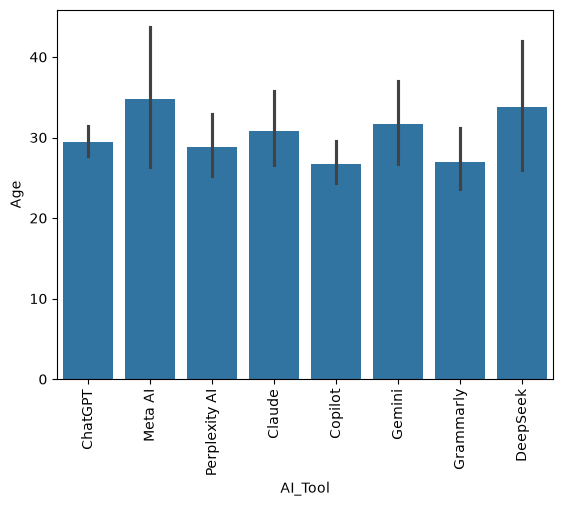

In [53]:
sns.barplot(x="AI_Tool",y="Age",data=df)
plt.xticks(rotation=90)

In [54]:
df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.0,Male,United Kingdom,Professional,Masters,Business Analyst,5421.0,ChatGPT,Office Work,2.0,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.0,Male,United States,Professional,Bachelors,Customer Support Specialist,8903.0,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,8.4,Yes
2,U0152,17.0,Male,Canada,Student,NaN,Computer Science Student,402.0,ChatGPT,Coding,1.0,NaN,20.0,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.0,Female,Brazil,Professional,Bachelors,Desenvolvedora De Software / Software Developer,1367.0,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes


<Axes: xlabel='AI_Usage_Hours_Per_Day', ylabel='Productivity_Score'>

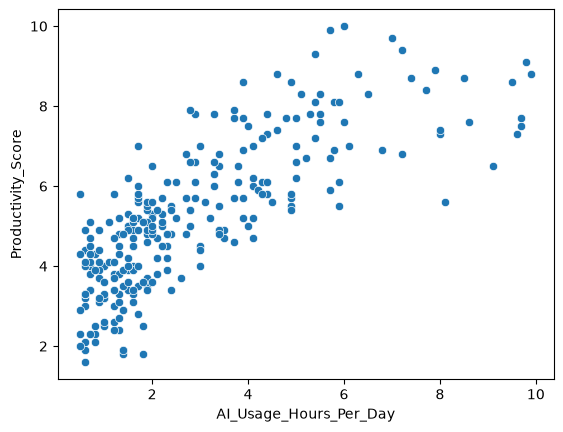

In [55]:
#  Does more daily AI usage mean higher productivity?

sns.scatterplot(x="AI_Usage_Hours_Per_Day",y="Productivity_Score",data=df)

In [56]:
df["AI_Usage_Hours_Per_Day"].corr(df["Productivity_Score"])

np.float64(0.7805440195220985)

hence it is closed to 1 , it's a strong link 


it's messy so have to fix it 


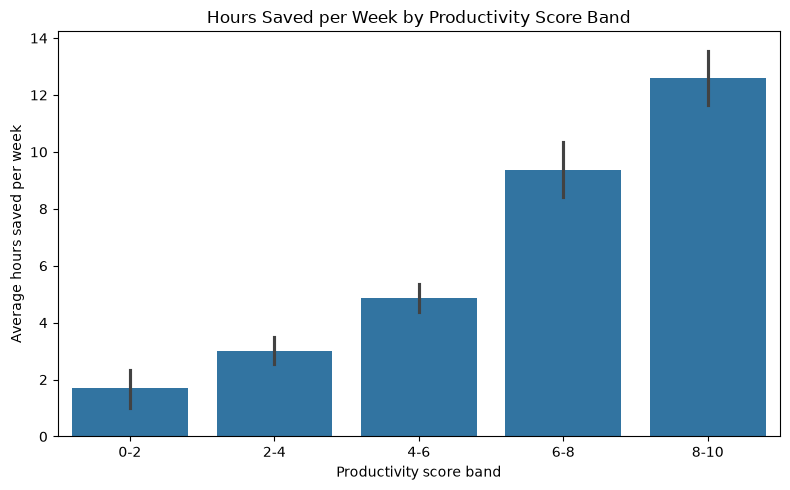

In [57]:
df["Productivity_Band"] = pd.cut(df["Productivity_Score"], bins=[0, 2, 4, 6, 8, 10],
                                 labels=["0-2", "2-4", "4-6", "6-8", "8-10"])

plt.figure(figsize=(8, 5))
sns.barplot(x="Productivity_Band", y="Time_Saved_Hours_Per_Week", data=df)
plt.title("Hours Saved per Week by Productivity Score Band")
plt.xlabel("Productivity score band")
plt.ylabel("Average hours saved per week")
plt.tight_layout()
plt.show()

In [58]:
# do paid users get better results than free users?

df["Plan"] = np.where(df["Monthly_AI_Cost"] > 0, "Paid", "Free")
df.loc[df["Monthly_AI_Cost"].isna(), "Plan"] = np.nan
print(df["Plan"].value_counts(dropna=False))

Plan
Free    147
Paid    129
NaN      12
Name: count, dtype: int64


In [59]:
df.groupby("Plan")[["Satisfaction_Score", "Productivity_Score", "Time_Saved_Hours_Per_Week"]].mean().round(1)

,Satisfaction_Score,Productivity_Score,Time_Saved_Hours_Per_Week
Plan,,,
Free,6.2,5.4,5.8
Paid,6.0,5.0,5.9


<Axes: xlabel='Satisfaction_Score', ylabel='Productivity_Score'>

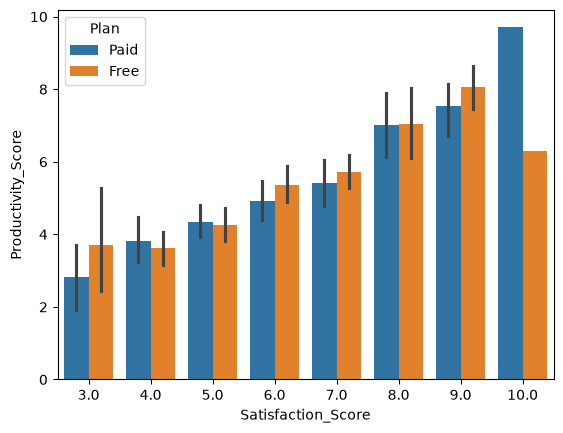

In [60]:
sns.barplot(x="Satisfaction_Score",y="Productivity_Score",hue="Plan",data=df)

<Axes: xlabel='Productivity_Score', ylabel='Time_Saved_Hours_Per_Week'>

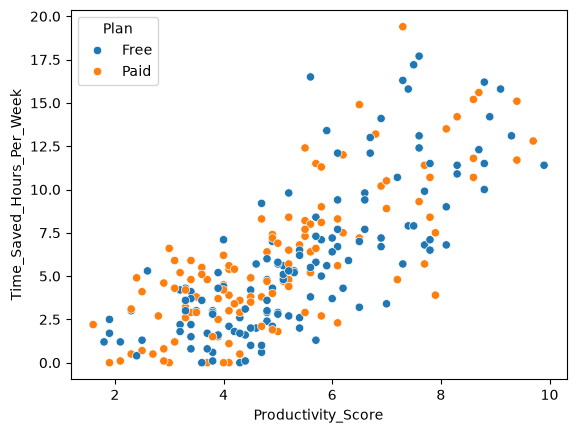

In [61]:
sns.scatterplot(x="Productivity_Score",y="Time_Saved_Hours_Per_Week",hue="Plan",data=df)

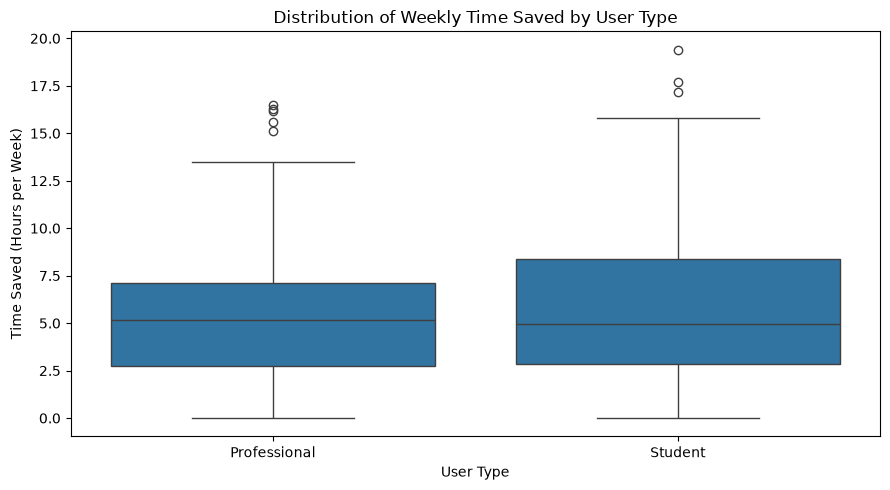

In [62]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x="User_Type",
    y="Time_Saved_Hours_Per_Week",
    data=df
)

plt.title("Distribution of Weekly Time Saved by User Type")
plt.xlabel("User Type")
plt.ylabel("Time Saved (Hours per Week)")

plt.tight_layout()
plt.show()

<Axes: xlabel='Productivity_Band', ylabel='count'>

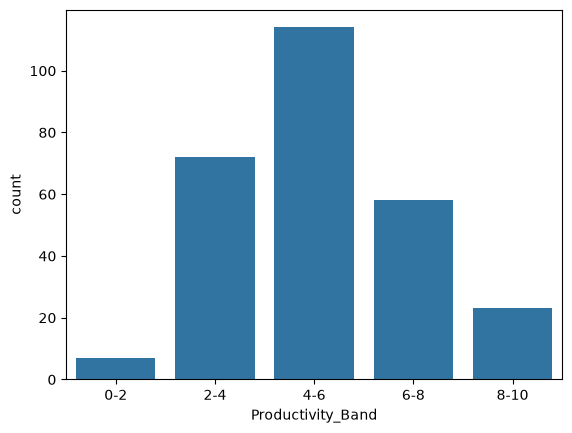

In [63]:
df["Productivity_Band"] = pd.cut(df["Productivity_Score"], bins=[0, 2, 4, 6, 8, 10],
                                 labels=["0-2", "2-4", "4-6", "6-8", "8-10"])
sns.countplot(x="Productivity_Band",data=df)

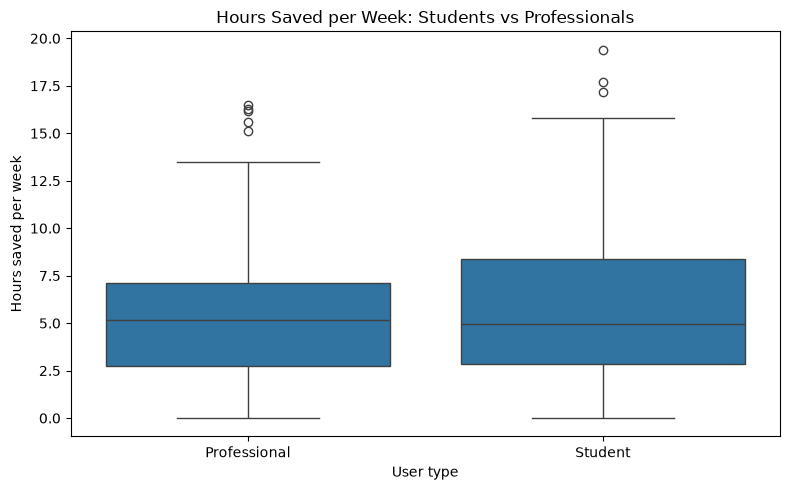

In [64]:
# to make the boxplot

plt.figure(figsize=(8, 5))
sns.boxplot(x="User_Type", y="Time_Saved_Hours_Per_Week", data=df)
plt.title("Hours Saved per Week: Students vs Professionals")
plt.xlabel("User type")
plt.ylabel("Hours saved per week")
plt.tight_layout()
plt.show()

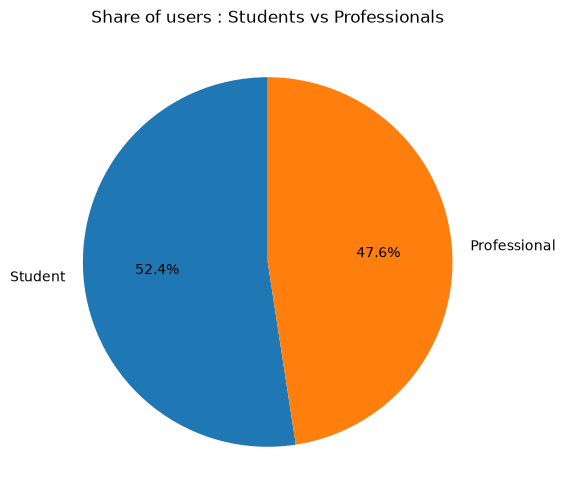

In [65]:
# to make pieplot

counts = df["User_Type"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(counts,labels=counts.index,autopct="%1.1f%%",startangle=90)
plt.title("Share of users : Students vs Professionals")
plt.show()


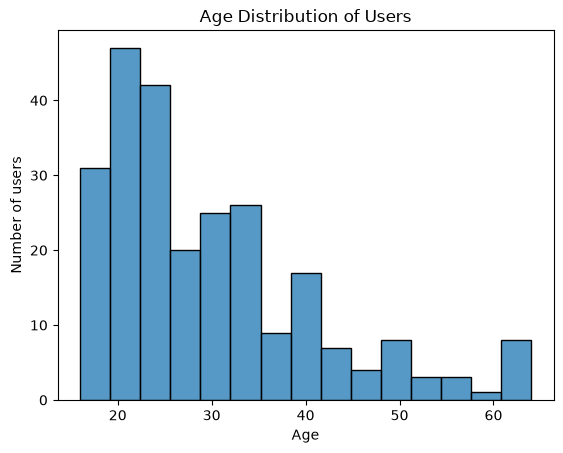

In [66]:
sns.histplot(df["Age"], bins=15)
plt.title("Age Distribution of Users")
plt.xlabel("Age")
plt.ylabel("Number of users")
plt.show()

<Axes: xlabel='AI_Usage_Hours_Per_Day', ylabel='Productivity_Score'>

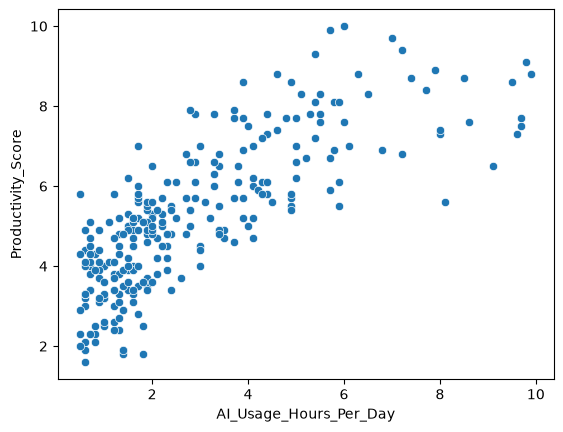

In [67]:
sns.scatterplot(x="AI_Usage_Hours_Per_Day", y="Productivity_Score", data=df)

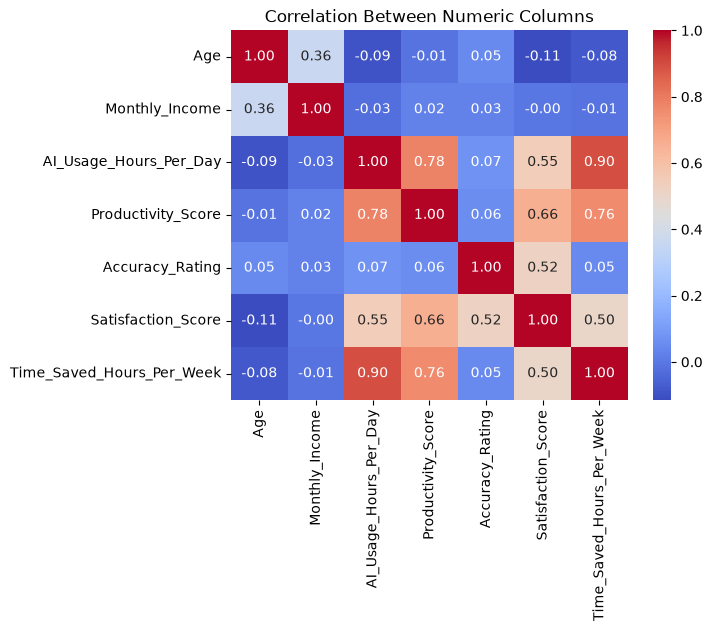

In [68]:
num = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Productivity_Score",
       "Accuracy_Rating", "Satisfaction_Score", "Time_Saved_Hours_Per_Week"]
sns.heatmap(df[num].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numeric Columns")
plt.show()

<Axes: xlabel='User_Type', ylabel='Satisfaction_Score'>

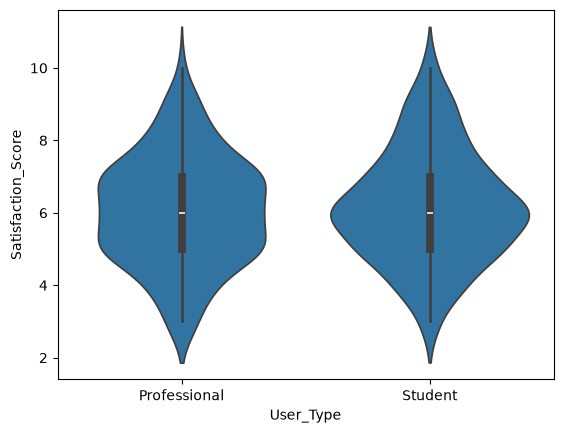

In [69]:
sns.violinplot(x="User_Type",y="Satisfaction_Score",data=df)

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'ChatGPT'),
  Text(1, 0, 'Meta AI'),
  Text(2, 0, 'Perplexity AI'),
  Text(3, 0, 'Claude'),
  Text(4, 0, 'Copilot'),
  Text(5, 0, 'Gemini'),
  Text(6, 0, 'Grammarly'),
  Text(7, 0, 'DeepSeek')])

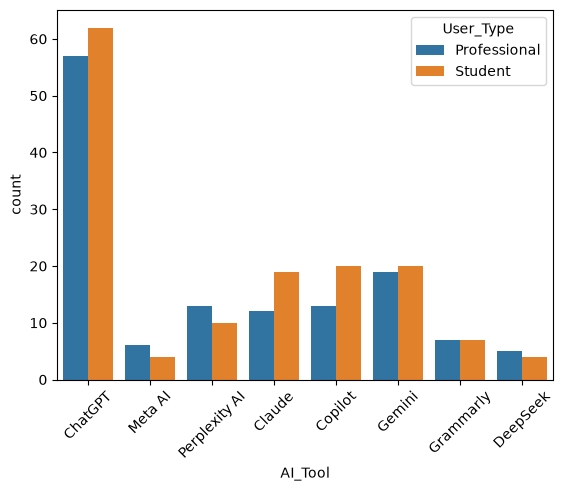

In [70]:
sns.countplot(x="AI_Tool", hue="User_Type", data=df)
plt.xticks(rotation=45)

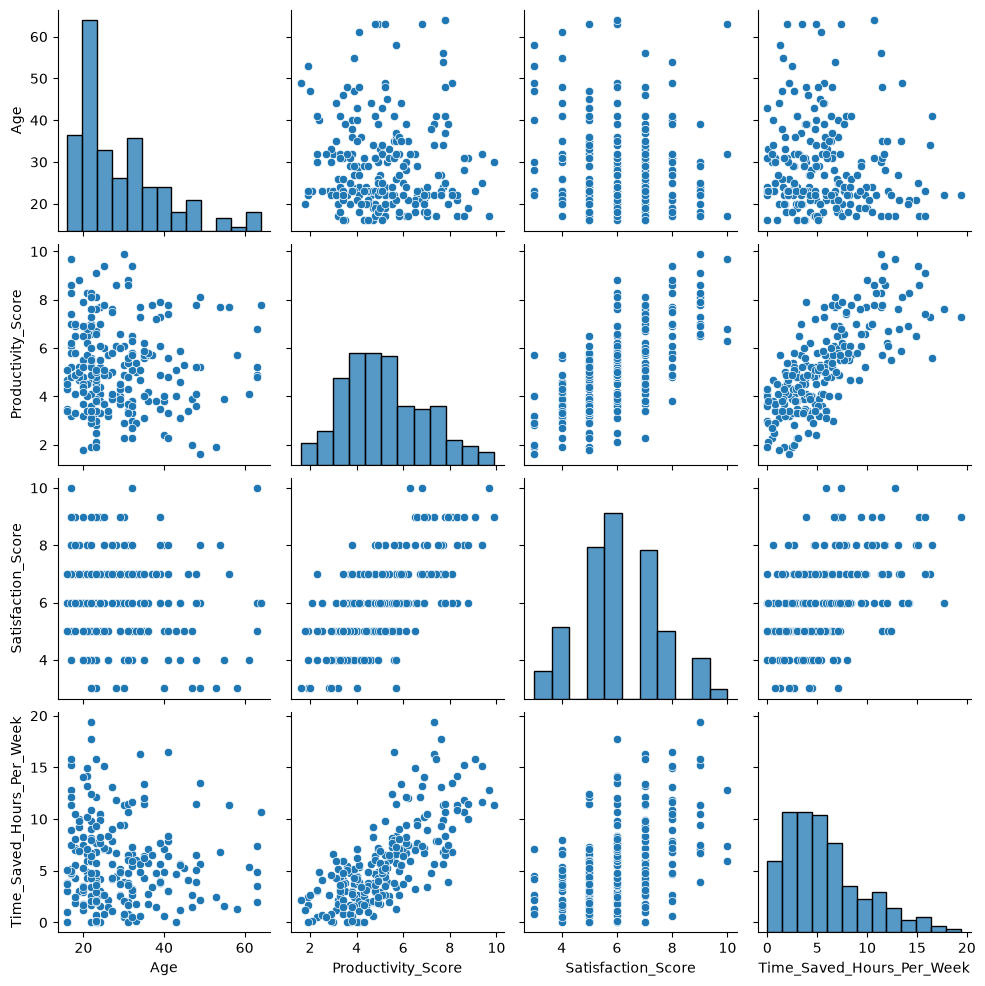

In [71]:
sns.pairplot(df[["Age", "Productivity_Score", "Satisfaction_Score", "Time_Saved_Hours_Per_Week"]].dropna())

In [72]:
# INSIGHTS
df.groupby("User_Type")["Time_Saved_Hours_Per_Week"].mean().round(1)

User_Type
Professional    5.6
Student         6.0
Name: Time_Saved_Hours_Per_Week, dtype: float64

In this insight, we can see as follows:-
- for the student is -> 6.0 hrs per week
- for thr Professional -> 5.6 hrs per week

In [73]:
df.groupby("AI_Tool")["Productivity_Score"].mean().round(2)

AI_Tool
ChatGPT          5.23
Claude           5.29
Copilot          5.51
DeepSeek         5.53
Gemini           5.06
Grammarly        5.11
Meta AI          5.15
Perplexity AI    4.64
Name: Productivity_Score, dtype: float64

Insights we can see here:-
- ChatGPT has 5.23 avg productivity score
- Claude has 5.29  avg productivity score
- Copilot has 5.51 avg productivity score
- DeepSeek has 5.53 avg productivity score
- Gemini has 5.06 avg productivity score
- Grammarly has 5.11 avgproductivity score
- Meta AI has 5.15 avg productivity Score
- Perplexity AI has 4.64 avg productivity score

In [74]:
df.groupby("AI_Tool")["Satisfaction_Score"].agg(["mean","count"]).round(2).sort_values("mean",ascending = False)

,mean,count
AI_Tool,,
Copilot,6.30,33
Grammarly,6.29,14
ChatGPT,6.26,115
DeepSeek,6.12,8
Claude,6.10,31
Meta AI,6.10,10
Perplexity AI,5.82,22
Gemini,5.68,38


- I found that average satisfaction is similar across AI tools (5.7 to 6.3 out of 10). Copilot (6.30, 33 users), Grammarly (6.29, 14 users) and ChatGPT (6.26, 115 users) are effectively tied, so the choice of tool seems to matter less than how people use it. Gemini scored lowest (5.68, 38 users). DeepSeek, Meta AI and Grammarly have under 15 users each, so their averages are less reliable.

In [75]:
df.groupby("AI_Tool")["Satisfaction_Score"].mean()

AI_Tool
ChatGPT          6.260870
Claude           6.096774
Copilot          6.303030
DeepSeek         6.125000
Gemini           5.684211
Grammarly        6.285714
Meta AI          6.100000
Perplexity AI    5.818182
Name: Satisfaction_Score, dtype: float64

In [76]:
compare = df.groupby("AI_Tool").agg(
    avg_satisfaction = ("Satisfaction_Score","mean"),
    avg_productivity = ("Productivity_Score","mean"),
    users = ("User_ID","count"),
)
print(compare)

               avg_satisfaction  avg_productivity  users
AI_Tool                                                 
ChatGPT                6.260870          5.231858    119
Claude                 6.096774          5.293103     31
Copilot                6.303030          5.512903     33
DeepSeek               6.125000          5.533333      9
Gemini                 5.684211          5.060526     39
Grammarly              6.285714          5.114286     14
Meta AI                6.100000          5.150000     10
Perplexity AI          5.818182          4.640000     23


In [77]:
compare = compare.round(2)
compare["rank_satisfaction"] = compare["avg_satisfaction"].rank(ascending=False)
compare["rank_productivity"] = compare["avg_productivity"].rank(ascending=False)
print(compare.sort_values("avg_satisfaction", ascending=False))

               avg_satisfaction  avg_productivity  users  rank_satisfaction  \
AI_Tool                                                                       
Copilot                    6.30              5.51     33                1.0   
Grammarly                  6.29              5.11     14                2.0   
ChatGPT                    6.26              5.23    119                3.0   
DeepSeek                   6.12              5.53      9                4.0   
Claude                     6.10              5.29     31                5.5   
Meta AI                    6.10              5.15     10                5.5   
Perplexity AI              5.82              4.64     23                7.0   
Gemini                     5.68              5.06     39                8.0   

               rank_productivity  
AI_Tool                           
Copilot                      2.0  
Grammarly                    6.0  
ChatGPT                      4.0  
DeepSeek                     1.0  

Copilot ranks near the top on both satisfaction and productivity, while Gemini and Perplexity rank near the bottom on both. Scores are close overall, and tools with under 15 users (DeepSeek, Meta AI, Grammarly) are too small to rank confidently.

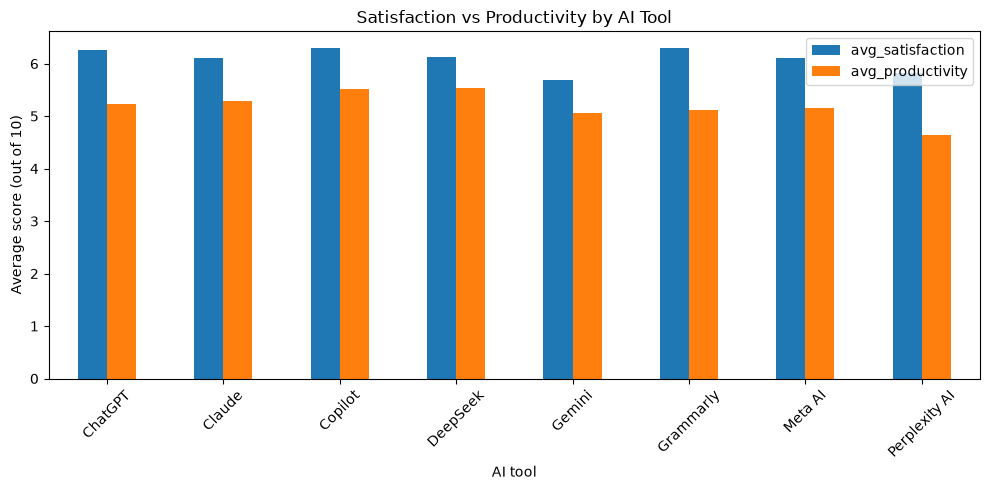

In [78]:
compare[["avg_satisfaction", "avg_productivity"]].plot(kind="bar", figsize=(10, 5))
plt.title("Satisfaction vs Productivity by AI Tool")
plt.xlabel("AI tool")
plt.ylabel("Average score (out of 10)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()